<a href="https://colab.research.google.com/github/renoegneo/MLclasswork/blob/main/ML_Practical_10_Variant_C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Количество объектов: 600
Количество исходных кластеров: 2


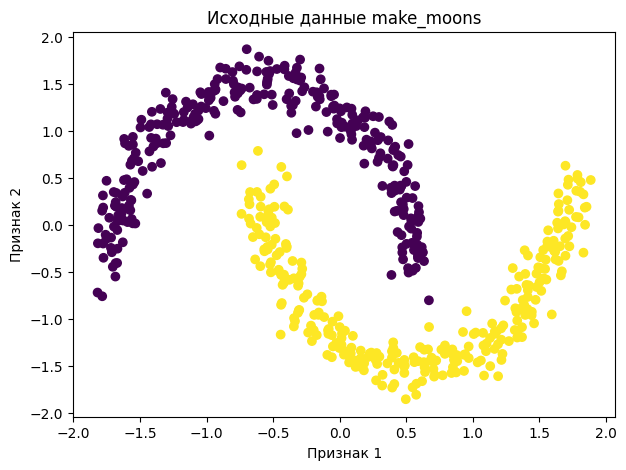

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score

from scipy.cluster.hierarchy import linkage, dendrogram

# Создаём данные сложной формы
X, y_true = make_moons(
    n_samples=600,
    noise=0.07,
    random_state=42
)

# Масштабируем данные
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Количество объектов:", len(X_scaled))
print("Количество исходных кластеров:", len(np.unique(y_true)))

plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_true, cmap='viridis')
plt.title("Исходные данные make_moons")
plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.show()

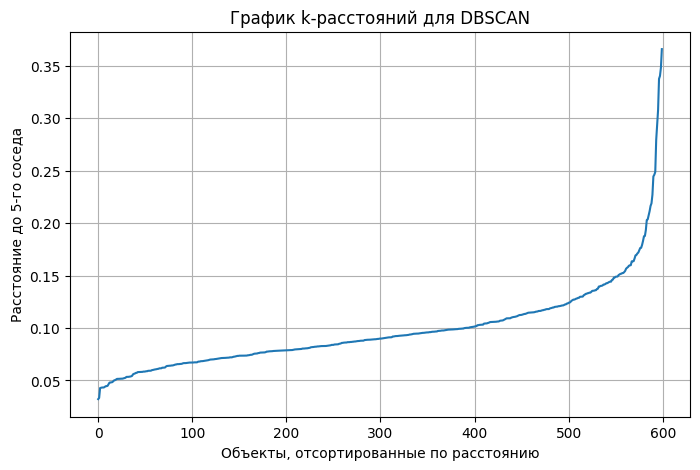

In [ ]:
min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.title("График k-расстояний для DBSCAN")
plt.xlabel("Объекты, отсортированные по расстоянию")
plt.ylabel("Расстояние до 5-го соседа")
plt.grid()
plt.show()

In [ ]:
# 1. K-Means
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)

# 2. DBSCAN
dbscan = DBSCAN(eps=0.25, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

# 3. Иерархическая кластеризация
hierarchical = AgglomerativeClustering(
    n_clusters=2,
    linkage='single'
)
labels_hierarchical = hierarchical.fit_predict(X_scaled)

print("K-Means: готово")
print("DBSCAN: готово")
print("Иерархическая кластеризация: готово")
print("Количество шумовых точек DBSCAN:", sum(labels_dbscan == -1))

K-Means: готово
DBSCAN: готово
Иерархическая кластеризация: готово
Количество шумовых точек DBSCAN: 2


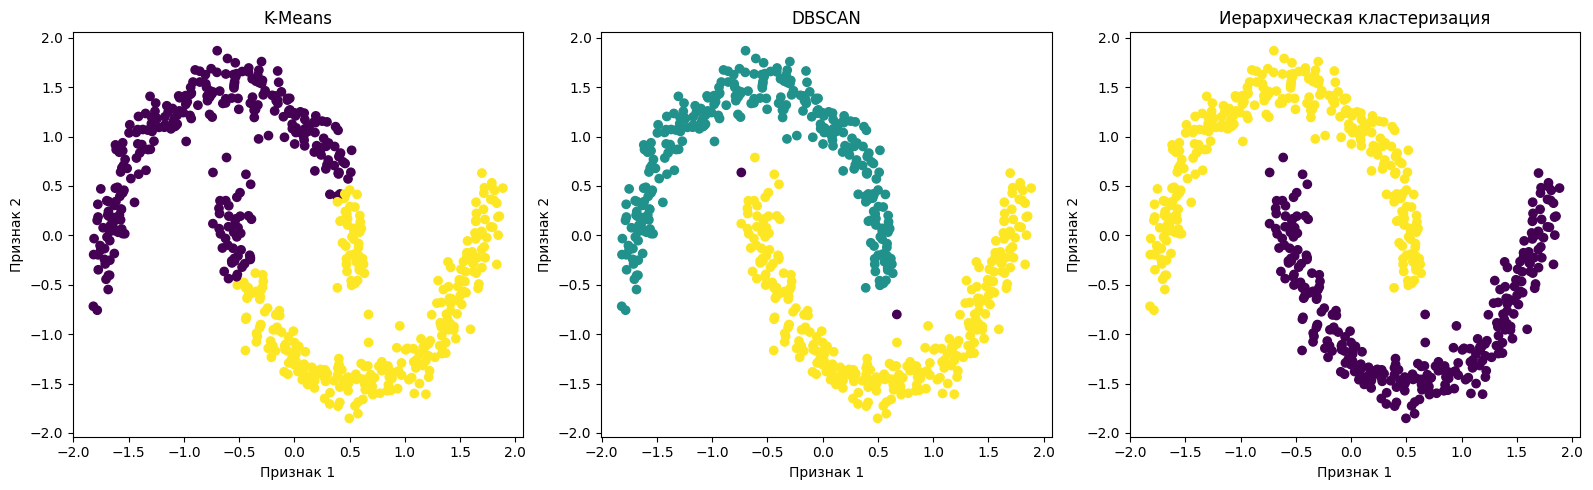

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1],
                c=labels_kmeans, cmap='viridis')
axes[0].set_title("K-Means")

axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1],
                c=labels_dbscan, cmap='viridis')
axes[1].set_title("DBSCAN")

axes[2].scatter(X_scaled[:, 0], X_scaled[:, 1],
                c=labels_hierarchical, cmap='viridis')
axes[2].set_title("Иерархическая кластеризация")

for ax in axes:
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")

plt.tight_layout()
plt.show()

In [ ]:
# K-Means
sil_kmeans = silhouette_score(X_scaled, labels_kmeans)
ari_kmeans = adjusted_rand_score(y_true, labels_kmeans)
db_kmeans = davies_bouldin_score(X_scaled, labels_kmeans)

# DBSCAN
mask = labels_dbscan != -1
dbscan_clusters = len(set(labels_dbscan) - {-1})

if dbscan_clusters >= 2:
    sil_dbscan = silhouette_score(X_scaled[mask], labels_dbscan[mask])
    db_dbscan = davies_bouldin_score(X_scaled[mask], labels_dbscan[mask])
else:
    sil_dbscan = np.nan
    db_dbscan = np.nan

ari_dbscan = adjusted_rand_score(y_true, labels_dbscan)

# Иерархическая кластеризация
sil_hier = silhouette_score(X_scaled, labels_hierarchical)
ari_hier = adjusted_rand_score(y_true, labels_hierarchical)
db_hier = davies_bouldin_score(X_scaled, labels_hierarchical)

# Общая таблица
results = pd.DataFrame({
    "Метод": ["K-Means", "DBSCAN", "Иерархическая"],
    "Silhouette": [sil_kmeans, sil_dbscan, sil_hier],
    "ARI": [ari_kmeans, ari_dbscan, ari_hier],
    "Davies-Bouldin": [db_kmeans, db_dbscan, db_hier]
})

display(results.round(3))

,Метод,Silhouette,ARI,Davies-Bouldin
0,K-Means,0.494,0.466,0.810
1,DBSCAN,0.389,0.993,1.017
2,Иерархическая,0.387,0.993,1.021


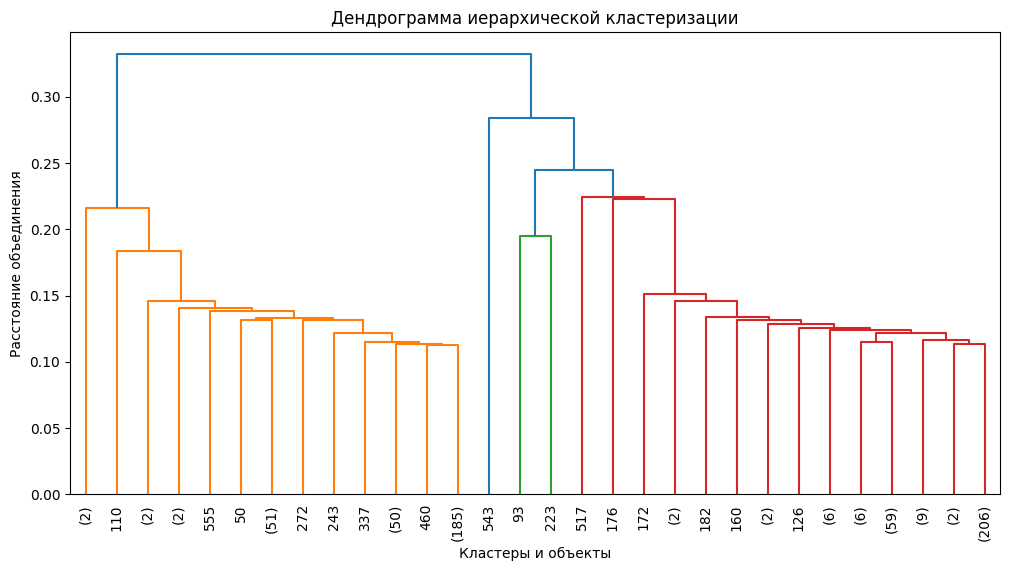

In [ ]:
Z = linkage(X_scaled, method='single', metric='euclidean')

plt.figure(figsize=(12, 6))
dendrogram(
    Z,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90
)

plt.title("Дендрограмма иерархической кластеризации")
plt.xlabel("Кластеры и объекты")
plt.ylabel("Расстояние объединения")
plt.show()

## Вывод

В данной работе были сравнены три метода кластеризации: K-Means, DBSCAN и иерархическая кластеризация.

Для эксперимента использовался набор данных make_moons, содержащий две группы точек сложной невыпуклой формы.

- **K-Means** показал худший результат, так как лучше подходит для компактных кластеров примерно круглой формы.
- **DBSCAN** смог обнаружить группы сложной формы и определить шумовые точки. Его результат зависит от правильного выбора eps и min_samples.
- **Иерархическая кластеризация** с методом single также хорошо выделила две группы. Дендрограмма показала последовательность объединения объектов и расстояния между ними, что позволяет дополнительно изучить структуру данных.

**Заключение:** для данных make_moons лучше подходят DBSCAN и иерархическая кластеризация с single linkage. K-Means менее эффективен из-за невыпуклой формы кластеров.

Ограничения методов: K-Means требует заранее указать количество кластеров; DBSCAN чувствителен к параметрам и плотности данных; single linkage может объединять группы через цепочки близких точек.